# Training Loop Diagnostics
Take a small model (nanoGPT) and a real loop, and make it tell the truth about itself.

Each part calls one script in `src/`. The numbers and plots below are the outputs of this run. See `README.md` for the written answers and `PLAN.md` for the method.

In [1]:
# Setup. On Colab this clones the repository; locally it only moves to the repository root.
import os, sys, pathlib
if 'google.colab' in sys.modules and not pathlib.Path('training-loop-diagnostics').exists():
    !git clone -q https://github.com/jssunil/training-loop-diagnostics
    %pip install -q -r training-loop-diagnostics/requirements.txt
root = pathlib.Path('training-loop-diagnostics') if pathlib.Path('training-loop-diagnostics').exists() else pathlib.Path.cwd()
if root.name == 'notebooks':
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root.resolve()))
import torch
from src.device import pick_device, env_info
print(env_info(pick_device()))

{'device': 'NVIDIA GeForce RTX 5070 Ti', 'torch': '2.7.0+cu128', 'cuda': '12.8', 'python': '3.13.5', 'os': 'Windows-11-10.0.26300-SP0', 'gpu_duty_limit': 0.6, 'gpu_mem_fraction': 0.6}


## Part 1: Every tensor shape in one step

In [2]:
from src import p1_shapes
_ = p1_shapes.run()

Device: NVIDIA GeForce RTX 5070 Ti
Symbols: B=4 sequences, T=16 positions, C=128 channels, nh=4 heads, hs=32 head size, V=65 characters, L=4 blocks

== Forward pass (attention tensors shown for block 0; blocks 1..L-1 are the same) ==
| tensor | shape | what each dimension means |
|---|---|---|
| idx | (4, 16) | B sequences x T token positions; each entry is a character id in [0, V) |
| y (targets) | (4, 16) | B x T: the correct next character id for each position (x moved one place right) |
| tok_emb | (4, 16, 128) | B x T x C: one C-number embedding vector for each token |
| pos_emb | (16, 128) | T x C: one C-number vector for each position; it is added to every sequence (broadcast over B) |
| x0 = tok_emb + pos_emb | (4, 16, 128) | B x T x C: the residual stream that enters block 0 |
| attn.q | (4, 4, 16, 32) | B x nh x T x hs: the query of each head, for each position (C = nh x hs) |
| attn.k | (4, 4, 16, 32) | B x nh x T x hs: the key of each head, for each position |
| attn.v | (4


== Backward pass: every parameter and its gradient (a gradient always has its weight's shape) ==
| parameter | weight shape | grad shape | what the dimensions mean |
|---|---|---|---|
| transformer.wte.weight | (65, 128) | (65, 128) | V x C: one 128-number vector per character; also the output head (tied) |
| transformer.wpe.weight | (128, 128) | (128, 128) | block_size x C: one vector per position 0..127 |
| transformer.h.0.ln_1.weight | (128,) | (128,) | C: one scale or shift per channel |
| transformer.h.0.ln_1.bias | (128,) | (128,) | C: one scale or shift per channel |
| transformer.h.0.attn.c_attn.weight | (384, 128) | (384, 128) | 3C x C: q, k and v projections stacked (out x in) |
| transformer.h.0.attn.c_attn.bias | (384,) | (384,) | 3C: bias of q, k and v |
| transformer.h.0.attn.c_proj.weight | (128, 128) | (128, 128) | C x C: merges the heads back into the residual stream (out x in) |
| transformer.h.0.attn.c_proj.bias | (128,) | (128,) | out: one bias per output feature |

## Part 2: Verify one gradient by hand

In [3]:
from src import p2_gradcheck
_ = p2_gradcheck.run()

Toy chain (worked example): autograd dL/dw1 = 64.000000, one-sided nudge 3.000->3.001 = 64.064000, central nudge = 64.000000



== float64: transformer.h.0.attn.c_attn.weight[3, 7] = -0.006069, loss = 4.212227, autograd grad = -1.8764120383e-05 ==
| eps | nudge (L(w+e)-L(w-e))/2e | autograd | abs error | rel error |
|---|---|---|---|---|
| 1e-01 | -1.8763944856e-05 | -1.8764120383e-05 | 1.76e-10 | 9.35e-06 |
| 1e-02 | -1.8764118614e-05 | -1.8764120383e-05 | 1.77e-12 | 9.42e-08 |
| 1e-03 | -1.8764120480e-05 | -1.8764120383e-05 | 9.70e-14 | 5.17e-09 |
| 1e-04 | -1.8764119147e-05 | -1.8764120383e-05 | 1.24e-12 | 6.58e-08 |
| 1e-05 | -1.8764190202e-05 | -1.8764120383e-05 | 6.98e-11 | 3.72e-06 |
| 1e-06 | -1.8764101384e-05 | -1.8764120383e-05 | 1.90e-11 | 1.01e-06 |
| 1e-07 | -1.8762769116e-05 | -1.8764120383e-05 | 1.35e-09 | 7.20e-05 |
Best agreement at eps=1e-03: relative error 5.17e-09



== float32: transformer.h.0.attn.c_attn.weight[3, 7] = -0.006069, loss = 4.212226, autograd grad = -1.8764130800e-05 ==
| eps | nudge (L(w+e)-L(w-e))/2e | autograd | abs error | rel error |
|---|---|---|---|---|
| 1e-01 | -1.9073486328e-05 | -1.8764130800e-05 | 3.09e-07 | 1.65e-02 |
| 1e-02 | -2.3841857910e-05 | -1.8764130800e-05 | 5.08e-06 | 2.71e-01 |
| 1e-03 | -2.3841857910e-04 | -1.8764130800e-05 | 2.20e-04 | 1.17e+01 |
| 1e-04 | 0.0000000000e+00 | -1.8764130800e-05 | 1.88e-05 | 1.00e+00 |
| 1e-05 | 2.3841857910e-02 | -1.8764130800e-05 | 2.39e-02 | 1.27e+03 |
| 1e-06 | 0.0000000000e+00 | -1.8764130800e-05 | 1.88e-05 | 1.00e+00 |
| 1e-07 | 0.0000000000e+00 | -1.8764130800e-05 | 1.88e-05 | 1.00e+00 |
Best agreement at eps=1e-01: relative error 1.65e-02

== float32_largest_grad: transformer.h.0.attn.c_attn.weight[308, 23] = 0.026108, loss = 4.212226, autograd grad = -3.3171892166e-02 ==
| eps | nudge (L(w+e)-L(w-e))/2e | autograd | abs error | rel error |
|---|---|---|---|---|
| 1e-01

## Part 3: Break gradient accumulation on purpose

Worked example: correct 2.6000, average of averages 3.0000 (15.4% too high); with equal lengths both give 3.0000 and 3.0000


Step-0 gradients: |correct - full|/|full| = 1.21e-07; |bug - full|/|full| = 0.321; cosine(bug, full) = 0.9500
Control, equal lengths [(16, 128), (16, 128), (16, 128)]: |bug - full|/|full| = 1.02e-07 (the bug hides when every micro-batch holds the same number of tokens)
Micro-batches per step: [(16, 128), (16, 128), (16, 8)] -> real tokens [2048, 2048, 128]; the short one gets 33% of the vote in the bug but holds 3.0% of the tokens


full    : train loss (token-weighted, mean of last 50 steps) 2.1230, final val loss 2.1186
correct : train loss (token-weighted, mean of last 50 steps) 2.1230, final val loss 2.1227
bug     : train loss (token-weighted, mean of last 50 steps) 2.3899, final val loss 2.3802
Final val gap bug - correct = +0.2575


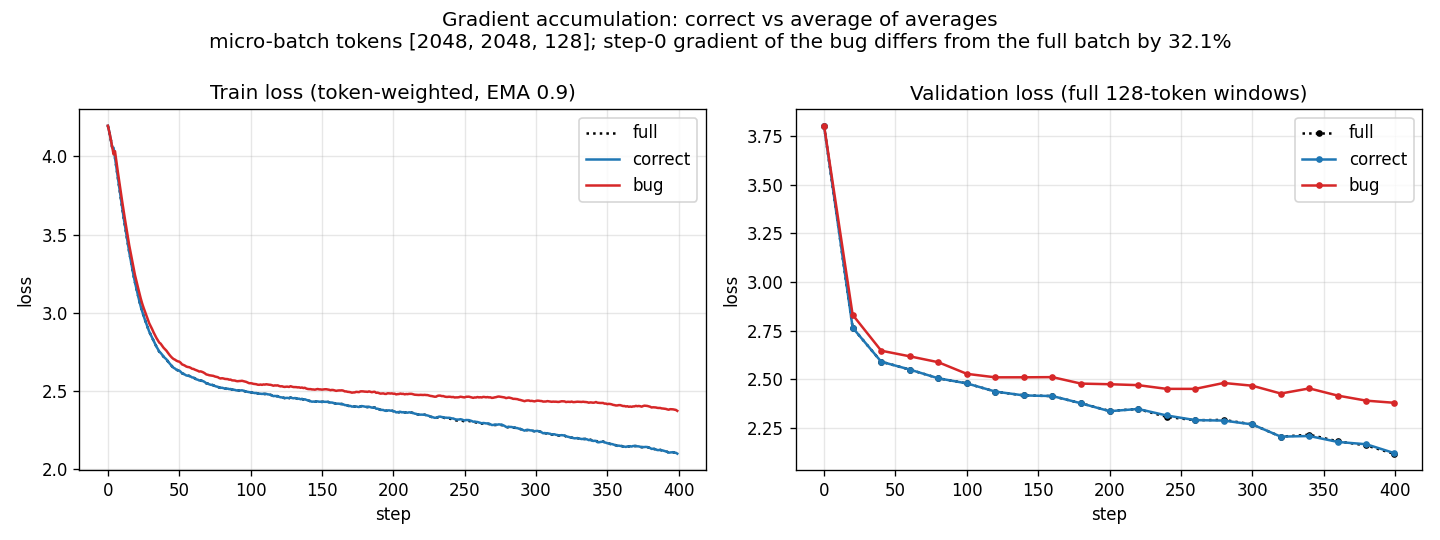

In [4]:
from src import p3_accum_bug
from IPython.display import Image, display
_ = p3_accum_bug.run()
display(Image('results/p3_accum_bug.png'))

## Part 4: The grad norm moves before the loss

[calm] 1500 steps, lr 0.003, seed 5, clip 1.0. Grad norm: median 0.468, max 10.460 at step 3; clip active on 13 of 1500 steps; mean loss of last 50 steps 1.576
[calm] No event: the grad norm never jumped while the loss stayed normal and then rose.


[hot] 1500 steps, lr 0.01, seed 6, clip 1.0. Grad norm: median 0.272, max 8.979 at step 1055; clip active on 63 of 1500 steps; mean loss of last 50 steps 2.602
[hot] 6 event(s). Clearest: step 1365: grad norm 5.809 (18.0x its median 0.322) while the loss 2.628 was still normal; the loss went above its band (2.652) 7 step(s) later, peak 2.657


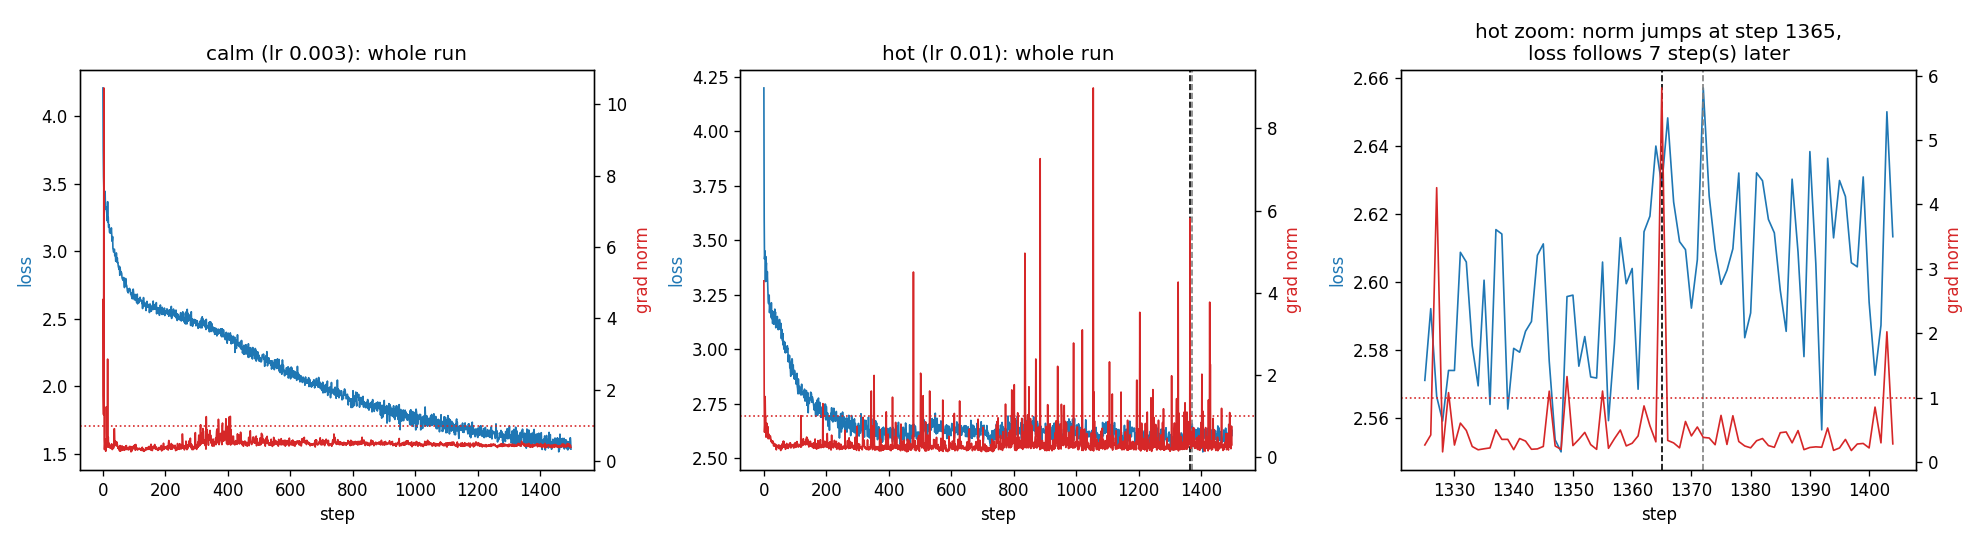

In [5]:
from src import p4_gradnorm
_ = p4_gradnorm.run()
display(Image('results/p4_gradnorm.png'))

## Part 5: MFU

In [6]:
from src import p5_mfu
_ = p5_mfu.run()

GPU duty limit 60% (rests between steps are not counted in any timing)
Device NVIDIA GeForce RTX 5070 Ti, dtype torch.bfloat16, N = 10,672,512 (non-embedding), FLOPs/token = 6N 64,035,072 + attention 7,077,888


Eager: 567,840 tokens/s, 28.9 ms/step, 40.38 TFLOP/s of model work
MFU = 23.0% (without attention 20.7%; nanoGPT estimate_mfu 23.0%) against peak 175.8 TFLOP/s [aggregator dense 16-bit tensor value (flopper.io), not checked against NVIDIA; the same site lists 87.9 for bf16, but this card measures about 96-98 on one 8192x8192 bf16 matmul (see measured_matmul_ceiling), so 87.9 cannot be the ceiling]


Measured 8192x8192 matmul ceiling: 96.9 TFLOP/s; model work is 41.7% of it


GPU busy 93% of wall time; 438 kernel launches per step
  matmul (gemm)                                  53.5% of GPU time
  attention (sdpa / flash)                        9.7% of GPU time
  optimizer (adam)                                5.0% of GPU time
  layernorm / softmax / gelu / cross-entropy     16.7% of GPU time
  other elementwise / copies                     15.1% of GPU time


torch.compile failed: TritonMissing: Cannot find a working triton installation. Either the package is not installed or it is too old. More information on installing Triton can be found at: https://github.com/triton-lang/triton


## Part 6: 0.1 in fp32, bf16 and fp8 E4M3

In [7]:
from src import p6_bits
_ = p6_bits.run()

0.1 = 1.6 x 2^-4. In binary, 1.6 = 1.1001 1001 1001 ... (the pattern 1001 repeats without end),
so no binary format can hold 0.1 exactly. Each format keeps a different number of those bits.

| format | sign | exponent field (e + bias) | mantissa | hex | stored value | relative error | torch agrees |
|---|---|---|---|---|---|---|---|
| fp32 | 0 | 01111011 (-4+127=123) | 10011001100110011001101 | 0x3DCCCCCD | 0.100000001490116 | 1.49e-08 | True (0x3DCCCCCD) |
| bf16 | 0 | 01111011 (-4+127=123) | 1001101 | 0x3DCD | 0.10009765625 | 9.77e-04 | True (0x3DCD) |
| fp8_e4m3 | 0 | 0011 (-4+7=3) | 101 | 0x1D | 0.1015625 | 1.56e-02 | True (0x1D) |


## Tests

In [8]:
!{sys.executable} -m pytest -q tests

......                                                                   [100%]
6 passed in 1.92s
